In [1]:
import numpy as np
import scipy as sp
from scipy.optimize import curve_fit

import pymc as pm
import matplotlib.pyplot as plt
import arviz as az

In this exercise you will be fitting model to data. The data was generated by drawing some random numbers in range (0,2) and calculating same function for each number. Then  the Gaussian noise with  mean zero and some fixed variance was added to each result.
The data is in the file `regression.txt`.

In [2]:
data = np.loadtxt('regression.txt')

## Problem 1

Fit polynomial of the second degree to the data. Use the `curve_fit` function from  `scipy.optimize`. Calculate the mean squared error (MSE).

In [3]:
x, y = data[:,0], data[:,1]

def quad(x, a, b, c):
    return a*x**2 + b*x + c

popt, pcov = curve_fit(quad, x, y)
a_fit, b_fit, c_fit = popt
y_pred = quad(x, a_fit, b_fit, c_fit)
mse = np.mean((y - y_pred)**2)

print(f"Optymalne współczynniki: a={a_fit:.4f}, b={b_fit:.4f}, c={c_fit:.4f}")
print(f"MSE = {mse:.6f}")

Optymalne współczynniki: a=-1.6098, b=1.2687, c=2.5897
MSE = 0.059665


## Problem 2 - Bayesian fit

Construct a PyMC model for the quadratic polynomial to fit to the data. Treat the $\sigma$ as an another parameter. Use the $\frac{1}{\sigma}$ prior. Use wide Gaussian priors for the polynomial coefficients.

Use `find_MAP` function to fit the model to the data. Compare the results with the result of `curve_fit`.

Generate the posterior samples for the model parameters using `sample` function.

Initializing NUTS using jitter+adapt_diag...


MAP estimates: {'a': array(-1.60953557), 'b': array(1.26819317), 'c': array(2.58983483), 'sigma_log__': array(-1.40950277), 'sigma': array(0.24426471)}


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [a, b, c, sigma]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 11 seconds.


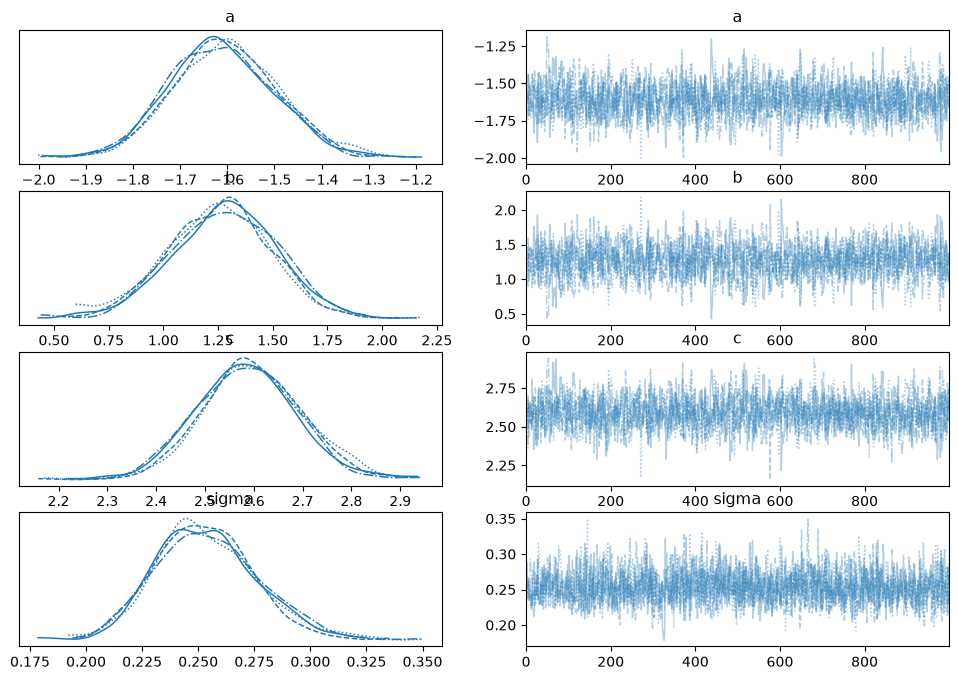

In [4]:
with pm.Model() as quad_model:
    a = pm.Normal('a', mu=0, sigma=10)
    b = pm.Normal('b', mu=0, sigma=10)
    c = pm.Normal('c', mu=0, sigma=10)
    sigma = pm.HalfFlat('sigma')
    mu = a * x**2 + b * x + c
    y_obs = pm.Normal('y_obs', mu=mu, sigma=sigma, observed=y)
    map_est = pm.find_MAP()
    print("MAP estimates:", map_est)
    trace = pm.sample(1000, tune=1000, return_inferencedata=True)

az.plot_trace(trace, var_names=['a','b','c','sigma']);
plt.show()

## Errors

Check the error of the fit in each of the

points. For each $x$ in $x\_test$ calculate the value of the polynomial using each posterior sample. Calculate the standard deviation. Mark this on the plot.

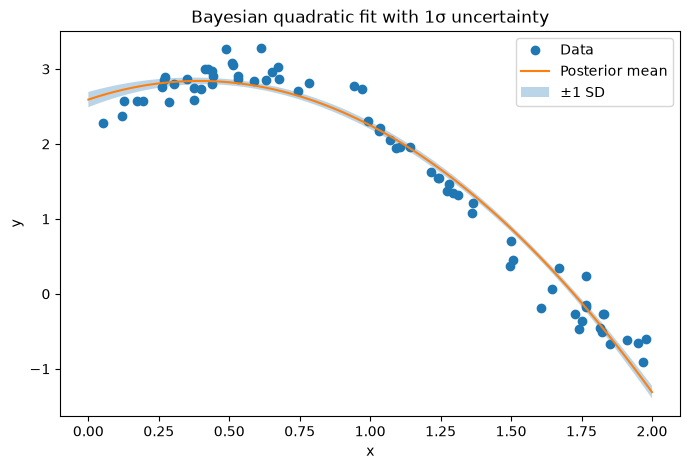

curve_fit:      -1.6098043300806273 1.2687218986782323 2.589691022042418
Bayesian MAP:   -1.6095355737874637 1.268193166856208 2.589834834175591


In [5]:
x_test = np.linspace(0,2,100)
a_s = trace.posterior['a'].values.flatten()
b_s = trace.posterior['b'].values.flatten()
c_s = trace.posterior['c'].values.flatten()

y_preds = np.array([
    a_s * x0**2 + b_s * x0 + c_s
    for x0 in x_test
])

y_mean = y_preds.mean(axis=1)
y_sd   = y_preds.std(axis=1)

plt.figure(figsize=(8,5))
plt.plot(x, y, 'o', label='Data')
plt.plot(x_test, y_mean, label='Posterior mean')
plt.fill_between(x_test, y_mean-y_sd, y_mean+y_sd, alpha=0.3, label='±1 SD')
plt.legend()
plt.xlabel('x')
plt.ylabel('y')
plt.title('Bayesian quadratic fit with 1σ uncertainty')
plt.show()

print("curve_fit:     ", a_fit, b_fit, c_fit)
print("Bayesian MAP:  ", map_est['a'], map_est['b'], map_est['c'])